In [39]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D , MaxPooling2D

In [40]:
x_train = np.loadtxt('/Users/gayatriapte/Downloads/Image Classification CNN Keras Dataset/input.csv', delimiter = ',')

y_train = np.loadtxt('/Users/gayatriapte/Downloads/Image Classification CNN Keras Dataset/labels.csv', delimiter = ',')

x_test = np.loadtxt('/Users/gayatriapte/Downloads/Image Classification CNN Keras Dataset/input_test.csv', delimiter = ',')

y_test = np.loadtxt('/Users/gayatriapte/Downloads/Image Classification CNN Keras Dataset/labels_test.csv' , delimiter = ',')

In [41]:
x_train = x_train.reshape(len(x_train), 100, 100, 3)
y_train = y_train.reshape(len(y_train), 1)
x_test = x_test.reshape(len(x_test), 100, 100, 3)
y_test = y_test.reshape(len(y_test), 1)

x_train = x_train / 255.0
x_test = x_test / 255.0

In [42]:
print('shape of x_train: :', x_train.shape)
print('shape of x_test: :', x_test.shape)
print('shape of y_train: :', y_train.shape)
print('shape of y_test: :', y_test.shape)

shape of x_train: : (2000, 100, 100, 3)
shape of x_test: : (400, 100, 100, 3)
shape of y_train: : (2000, 1)
shape of y_test: : (400, 1)


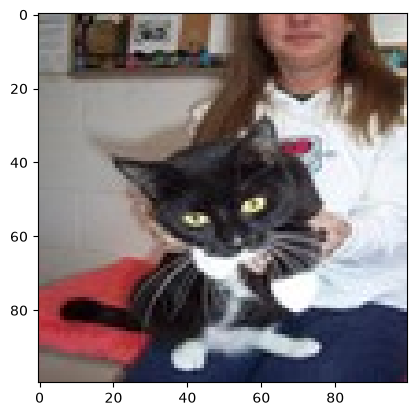

In [43]:
idx = random.randint(1, len(x_train))
plt.imshow(x_train[idx, :])
plt.show()

In [44]:
model = Sequential([
    Conv2D(32, (3,3), activation ='relu', input_shape = (100, 100, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(32, (3, 3), activation = 'relu'),
    MaxPooling2D((2,2)),
    Flatten(),

    Dense(64, activation= 'relu'),
    Dense(1, activation = 'sigmoid')
])


In [45]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [46]:
model.fit(x_train , y_train, epochs = 5, batch_size = 64)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.5245 - loss: 0.7335
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.6055 - loss: 0.6844
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.6465 - loss: 0.6449
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.6540 - loss: 0.6280
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.7115 - loss: 0.5684


In [47]:
model.evaluate(x_test, y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6875 - loss: 0.5852


[0.5851961374282837, 0.6875]

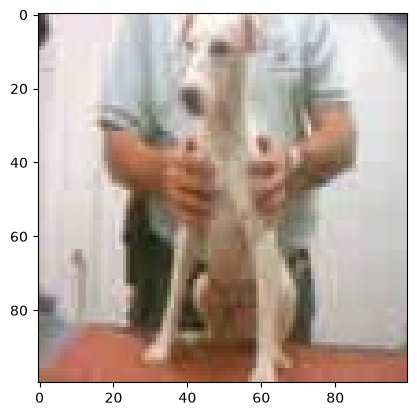

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Our model says it is : dog


In [48]:
idx2 = random.randint(0, len(y_test))
plt.imshow(x_test[idx2,:])
plt.show()
y_pred = model.predict(x_test[idx2, :].reshape(1, 100, 100, 3))
y_pred = y_pred > 0.5
if (y_pred == 0):
    pred = 'dog'
else:
    pred = 'cat'
print('Our model says it is :', pred)